        # Cognitive Science (1204 427) — Lab 13
        ## Semantic Networks and Spreading Activation

        **ระดับ:** ปริญญาตรี  
        **เวลาที่แนะนำ:** 150–180 นาที  
        **รูปแบบ:** งานเดี่ยวบน Google Colab/Jupyter Notebook  
        **แพ็กเกจหลัก:** `numpy, pandas, matplotlib, networkx`

        ### แนวคิดสำคัญ

        Semantic Network แทน Concept ด้วย Node และความสัมพันธ์ด้วย Edge ส่วน Spreading Activation จำลองการที่การกระตุ้นจาก Cue แพร่ไปยัง Concept ที่เชื่อมโยงกัน

        ### วัตถุประสงค์

        วิเคราะห์ Centrality, Shortest Paths, Activation และผลของ Network Lesion ต่อโครงสร้างความรู้

        ### งานที่ต้องทำ

        1. สร้าง Semantic Network แบบ Weighted
2. คำนวณ Degree, Closeness และ Betweenness
3. จำลอง Spreading Activation
4. ลบ Semantic Bridge และวิเคราะห์ Connectivity
5. Required Extension: เปรียบเทียบ Cue Words และค่า Decay หลายค่า

        > ไปที่ [Google Colab](https://colab.research.google.com) แล้วเลือก **File → Upload notebook** เพื่อเปิดไฟล์นี้


## ข้อมูลนิสิตและคำชี้แจง

- ชื่อ–สกุล: วชิรวิทย์ วงค์แสง
- รหัสนิสิต: 67011212055
- กลุ่มเรียน: 1

1. เปลี่ยน `STUDENT_ID` เป็นรหัสนิสิตของตนเองก่อนรันโปรแกรม
2. รหัส 4 หลักสุดท้ายใช้เป็น Random Seed ทำให้ข้อมูลแต่ละคนแตกต่างกัน
3. รันเซลล์จากบนลงล่างและเก็บ Output ไว้ในไฟล์ที่ส่ง
4. ทุกกราฟต้องมีชื่อกราฟ ชื่อแกน หน่วย และคำอธิบาย
5. ห้ามสรุปผลเกินกว่าหลักฐานจากข้อมูลหรืออ้างว่าข้อมูลจำลองเป็นข้อมูลมนุษย์จริง
6. ส่งไฟล์ `.ipynb` และ `.pdf` โดยตั้งชื่อ `StudentID_LabXX.ipynb`


In [1]:
STUDENT_ID = 67011212055  # รหัสนิสิต: วชิรวิทย์ วงค์แสง
sid = str(STUDENT_ID).strip()
if not sid.isdigit() or len(sid) < 4:
    raise ValueError("STUDENT_ID ต้องเป็นตัวเลขอย่างน้อย 4 หลัก")
seed = int(sid[-4:])
print(f"Student ID: {sid} | Random seed: {seed}")


Student ID: 67011212055 | Random seed: 2055


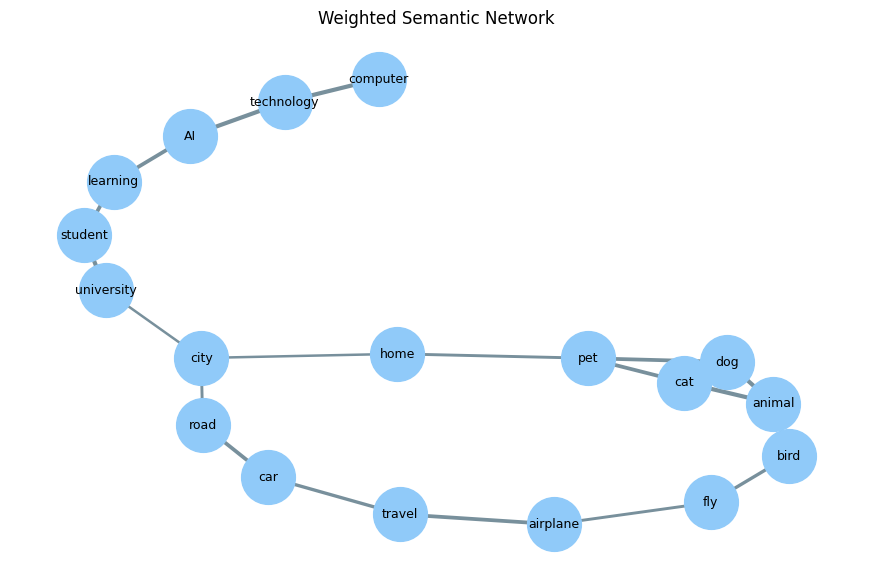

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    import networkx as nx
except ImportError:
    import importlib, site, subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "networkx"])
    site.addsitedir(site.getusersitepackages())
    importlib.invalidate_caches()
    import networkx as nx

edges = [
    ("dog", "animal", 1.0), ("cat", "animal", 1.0), ("bird", "animal", .9),
    ("dog", "pet", .9), ("cat", "pet", .9), ("pet", "home", .7),
    ("bird", "fly", .8), ("airplane", "fly", .7), ("airplane", "travel", .9),
    ("car", "travel", .8), ("car", "road", .9), ("road", "city", .7),
    ("home", "city", .6), ("computer", "technology", 1.0), ("AI", "technology", 1.0),
    ("AI", "learning", .9), ("student", "learning", .9), ("student", "university", 1.0),
    ("university", "city", .6),
]
G = nx.Graph()
for u, v, strength in edges:
    G.add_edge(u, v, strength=strength, distance=1 / strength)

pos = nx.spring_layout(G, seed=seed, weight="strength")
widths = [G[u][v]["strength"] * 3 for u, v in G.edges()]
plt.figure(figsize=(11, 7))
nx.draw_networkx(G, pos, node_color="#90caf9", node_size=1500, font_size=9, width=widths, edge_color="#78909c")
plt.title("Weighted Semantic Network"); plt.axis("off"); plt.show()


In [3]:
centrality = pd.DataFrame({
    "degree": pd.Series(nx.degree_centrality(G)),
    "closeness": pd.Series(nx.closeness_centrality(G, distance="distance")),
    "betweenness": pd.Series(nx.betweenness_centrality(G, weight="distance")),
}).sort_values("betweenness", ascending=False)
display(centrality.round(4))
path = nx.shortest_path(G, "dog", "AI", weight="distance")
print("Shortest semantic path:", " -> ".join(path))


,degree,closeness,betweenness
city,0.1765,0.2447,0.5735
university,0.1176,0.2139,0.4412
student,0.1176,0.1944,0.3824
home,0.1176,0.2197,0.3162
learning,0.1176,0.1725,0.3088
pet,0.1765,0.2028,0.2794
road,0.1176,0.2144,0.2574
AI,0.1176,0.1519,0.2206
car,0.1176,0.1963,0.2059
travel,0.1176,0.1840,0.1618


Shortest semantic path: dog -> pet -> home -> city -> university -> student -> learning -> AI


,activation
dog,0.3693
cat,0.1693
animal,0.1310
pet,0.1173
bird,0.0958
home,0.0713
airplane,0.0147
road,0.0092
university,0.0079
fly,0.0079


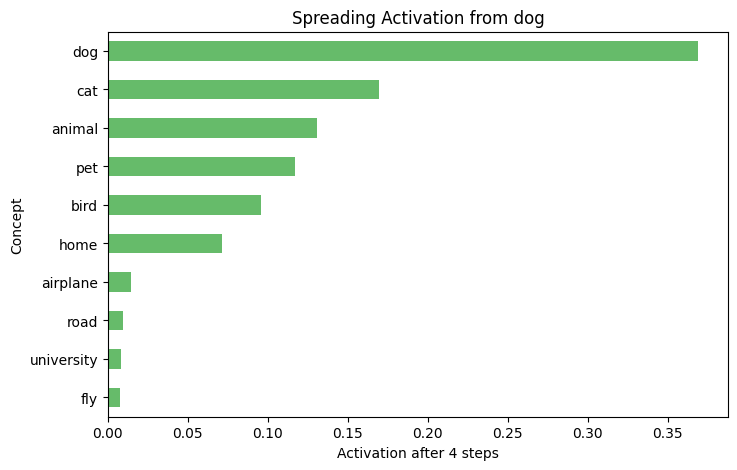

In [4]:
def spread_activation(graph, cue, decay=0.8, steps=4):
    nodes = list(graph.nodes())
    adjacency = nx.to_numpy_array(graph, nodelist=nodes, weight="strength")
    transition = adjacency / adjacency.sum(axis=1, keepdims=True)
    activation = np.zeros(len(nodes)); cue_i = nodes.index(cue); activation[cue_i] = 1.0
    for _ in range(steps):
        activation = decay * transition.T @ activation
        activation[cue_i] += 0.20
    return pd.Series(activation, index=nodes).sort_values(ascending=False)

activation = spread_activation(G, "dog")
display(activation.rename("activation").to_frame().round(4))
activation.head(10).sort_values().plot(kind="barh", figsize=(8, 5), color="#66bb6a")
plt.xlabel("Activation after 4 steps"); plt.ylabel("Concept"); plt.title("Spreading Activation from dog")
plt.show()


In [5]:
target = centrality.index[0]
damaged = G.copy(); damaged.remove_node(target)
comparison = pd.DataFrame({
    "measure": ["nodes", "components", "largest_component"],
    "original": [G.number_of_nodes(), nx.number_connected_components(G), len(max(nx.connected_components(G), key=len))],
    "after_lesion": [damaged.number_of_nodes(), nx.number_connected_components(damaged), len(max(nx.connected_components(damaged), key=len))],
})
print("Removed semantic bridge:", target); display(comparison)


Removed semantic bridge: city


,measure,original,after_lesion
0,nodes,18,17
1,components,1,2
2,largest_component,18,11


## Required Extension

เปรียบเทียบ Cue Words `dog`, `city` และ `AI` ที่ค่า Decay 0.50, 0.80 และ 0.95 สร้างตาราง Top-5 Activated Concepts และอธิบายผลของ Cue/Decay


,cue,decay,top5_concepts
0,dog,0.50,"dog, animal, pet, cat, bird"
1,dog,0.80,"dog, cat, animal, pet, bird"
2,dog,0.95,"dog, cat, bird, animal, pet"
3,city,0.50,"city, road, university, home, car"
4,city,0.80,"city, car, student, road, pet"
5,city,0.95,"city, car, student, pet, road"
6,AI,0.50,"AI, technology, learning, computer, student"
7,AI,0.80,"AI, computer, technology, student, learning"
8,AI,0.95,"AI, computer, student, technology, learning"


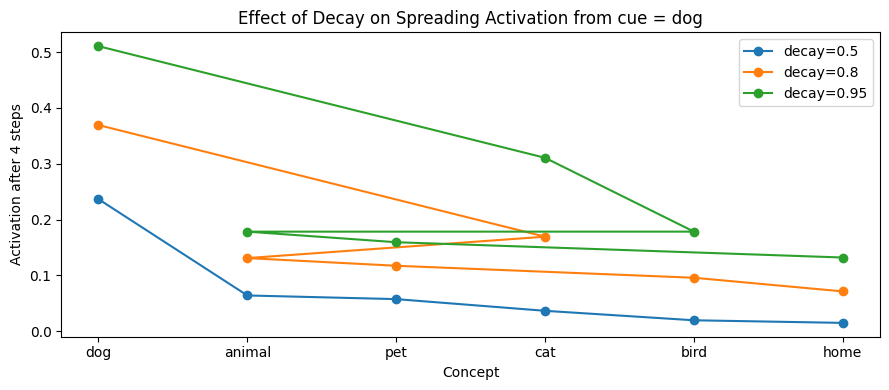

In [6]:
# ===== Required Extension: เปรียบเทียบ Cue Words x Decay =====
cue_words = ["dog", "city", "AI"]
decays = [0.50, 0.80, 0.95]

rows = []
for cue in cue_words:
    for d in decays:
        top5 = spread_activation(G, cue, decay=d).head(5)
        rows.append({
            "cue": cue,
            "decay": d,
            "top5_concepts": ", ".join(top5.index),
        })
cue_decay_table = pd.DataFrame(rows)
display(cue_decay_table)

# กราฟ: ค่า activation ของ top-5 concept จาก cue = "dog" ที่ decay ต่างกัน
plt.figure(figsize=(9, 4))
for d in decays:
    series = spread_activation(G, "dog", decay=d).head(6)
    plt.plot(series.index, series.values, marker="o", label=f"decay={d}")
plt.xlabel("Concept")
plt.ylabel("Activation after 4 steps")
plt.title("Effect of Decay on Spreading Activation from cue = dog")
plt.legend()
plt.tight_layout()
plt.show()


## คำถามวิเคราะห์ Lab 13

**1. Centrality สามชนิดให้ความหมายของ Concept Importance ต่างกันอย่างไร**

Degree นับจำนวนเพื่อนบ้านตรง (concept ที่เชื่อมโยงเยอะ), Closeness วัดว่าเดินทางไปถึง concept อื่นทั้งเครือข่ายได้ใกล้แค่ไหน (เข้าถึงเร็ว), Betweenness วัดว่าอยู่บนเส้นทางสั้นที่สุดระหว่างคู่อื่นบ่อยแค่ไหน (เป็นสะพาน/ตัวกลาง) แต่ละอันนิยาม "สำคัญ" คนละมุม

**2. Concept ใดเป็น Semantic Bridge และมีหลักฐานอะไร**

city ครับ มี betweenness สูงสุด (~0.57) นำ university (~0.44) กับ student (~0.38) ชัดเจน เพราะ city เชื่อมกลุ่มความหมายต่างกลุ่ม (การเดินทาง–ที่อยู่อาศัย–การศึกษา/เทคโนโลยี) เข้าด้วยกัน เส้นทาง dog→AI ก็ต้องผ่าน city

**3. Activation จาก Cue ต่างกันอย่างไรเมื่อเปลี่ยน Decay**

Decay ต่ำ (0.50) การกระตุ้นแพร่ไปไม่ไกล เน้นอยู่ที่ cue กับเพื่อนบ้านใกล้ๆ ส่วน decay สูง (0.95) แพร่ไปได้ไกลและกว้างกว่า concept ห่างๆ ได้ activation มากขึ้น แต่ลำดับ top ก็ยังเป็นเพื่อนบ้านใกล้ก่อน (dog→cat/animal/pet) และ cue ต่างกันก็ activate คนละกลุ่ม (city→car/road, AI→computer/technology)

**4. Network Lesion ส่งผลต่อการเข้าถึงความรู้อย่างไร**

พอลบ semantic bridge (city ที่ betweenness สูงสุด) เครือข่ายแตกเป็นหลาย component กลุ่มความหมายบางกลุ่มถูกตัดขาด ทำให้แพร่การกระตุ้น/เดินทางระหว่างกลุ่มยากขึ้น เปรียบเหมือนความเสียหายเฉพาะจุดของ semantic memory ที่ทำให้เข้าถึงความรู้บางส่วนไม่ได้

**5. Network Model แทน Semantic Memory ของมนุษย์ไม่ครบในด้านใด**

จริงๆ ความสัมพันธ์มีทิศทางและไม่สมมาตร (dog→animal แข็งกว่า animal→dog), เปลี่ยนตามบริบท/ประสบการณ์, เป็น distributed ในสมองไม่ใช่ node เดี่ยว, และมีมิติอารมณ์/การรับรู้ ส่วนโมเดลนี้เป็นกราฟไม่มีทิศ น้ำหนักคงที่ 18 คำ เลยง่ายกว่าจริงมาก

## Reflection และ Checklist ก่อนส่ง

**Reflection:**

ส่วนที่ยากสุดคือ Required Extension ตอนวนเปรียบเทียบ cue สามคำ × decay สามค่า ต้องระวังเรียกฟังก์ชัน spread_activation ให้ส่ง decay เข้าไปถูก และจัดตารางให้อ่านง่าย พอทำเสร็จเห็นชัดว่า cue ต่างกัน activate คนละกลุ่มความหมายเลย

สิ่งที่เข้าใจมากขึ้นคือ spreading activation อธิบาย semantic priming ได้เป็นรูปธรรม เห็นว่าคำที่อยู่ใกล้ cue ในเครือข่ายถูกกระตุ้นก่อนและมากกว่า ตรงกับที่คนนึกคำที่สัมพันธ์กันได้เร็วขึ้น และ decay ก็เหมือนคุมว่าการกระตุ้นแพร่ไปไกลแค่ไหน

ถ้าทำซ้ำ อยากลองเครือข่ายที่ใหญ่ขึ้นและมีทิศทาง (directed) เพื่อให้ใกล้ความจริงของ semantic memory มากขึ้น และลองวัดว่าการลบ node ที่ต่างกันกระทบ connectivity ต่างกันแค่ไหน

### เกณฑ์ประเมิน

| ด้าน | คะแนน |
|---|---:|
| ความถูกต้องของโปรแกรมและผลลัพธ์ | 35 |
| กระบวนการวิเคราะห์และความสมเหตุสมผล | 20 |
| กราฟ ตาราง และการสื่อสารผล | 15 |
| การตีความตามหลัก Cognitive Science | 20 |
| คุณภาพโค้ดและ Reflection | 10 |
| **รวม** | **100** |

- [x] เปลี่ยน `STUDENT_ID` แล้ว
- [x] รันทุกเซลล์โดยไม่มี Error
- [x] ทำ Required Extension สำเร็จ
- [x] ตอบคำถามทุกข้อด้วยถ้อยคำของตนเอง
- [x] ตรวจไฟล์ `.ipynb` และ `.pdf` ก่อนส่ง
